# Projeto 2 — Alocação de alunos a projetos

**Universidade de Brasília · Teoria e Aplicação de Grafos · Turma A · 2026/2**  
**Professor:** Díbio Leandro Borges

| Integrante | Matrícula |
| --- | --- |
| Felipe Da Graça Costa | 252009161 |
| Arthur Santos Almeida | 242009990 |


## Especificação Base

O projeto consiste em distribuir os 200 alunos entre os 50 projetos do arquivo
`entradaProj2.26TAG.txt`. Cada aluno indica até três preferências, e cada projeto
informa suas vagas e a nota mínima para participar.

## Metodologia

1. Ler os projetos e as preferências dos alunos.
2. Implementar as duas direções de Gale–Shapley: alunos propondo e projetos propondo.
3. Após cada emparelhamento inicial, realizar dez iterações com caminhos alternados
   para tentar alocar mais alunos sem criar pares bloqueadores.
4. Exibir os grafos das rodadas e exemplos de propostas aceitas e rejeitadas.
5. Calcular o índice de preferência por projeto e mostrar a matriz final dos
   emparelhamentos. A direção dos projetos será a proposta final.

## Implementação

Vamos iniciar importando as bibliotecas usadas para desenhar os grafos e exibir as
tabelas. O notebook requer Python 3.10 ou superior. A leitura usa o arquivo de entrada
local, quando disponível; no Colab, baixa o arquivo automaticamente do GitHub.

In [1]:
# Se necessário, descomente para instalar as bibliotecas:
# %pip install matplotlib networkx

from pathlib import Path
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display

get_ipython().run_line_magic("matplotlib", "inline")

Vamos representar os dados pelas classes `Aluno` e `Projeto`. O aluno guarda sua
nota, suas preferências e o projeto ao qual está alocado. O projeto guarda as vagas,
a nota mínima e os alunos aceitos. Assim, uma alocação aparece tanto em
`aluno.projeto` quanto em `projeto.alunos`.

O método `checa_preferencia_aluno` verifica se o projeto pode aceitar uma proposta.
Quando há vaga, retorna a posição para inclusão. Quando está cheio, retorna a posição
do pior aluno, desde que o novo candidato tenha nota maior. Nos demais casos,
retorna `None`. Notas iguais mantêm o aluno atual.

In [2]:
from __future__ import annotations

from typing import TYPE_CHECKING

class Projeto:

    def __init__(self, label: str, vagas: int, nota_min: int):

        self.label = label
        self.vagas = vagas
        self.nota_min = nota_min
        self.alunos: list[Aluno] = []
        self.candidatos: list[Aluno] = []

    def __str__(self) -> str:
        return "{}: Vagas({}), Nota Mínima({})".format(
            self.label, self.vagas, self.nota_min
        )

    def __repr__(self) -> str:
        return "{}: Vagas({}), Nota Mínima({})".format(
            self.label, self.vagas, self.nota_min
        )

    def tem_vaga(self) -> bool:
        return len(self.alunos) < self.vagas

    def monta_candidatos(self, alunos: list[Aluno]) -> None:

        candidatos: list[Aluno] = []
        for aluno in alunos:
            if self in aluno.preferencias and aluno.nota >= self.nota_min:
                candidatos.append(aluno)

        candidatos.sort(key=lambda aluno: aluno.nota, reverse=True)

        self.candidatos = candidatos

    def aluno_elegivel(self, aluno: Aluno) -> bool:
        return aluno.nota >= self.nota_min

    def checa_preferencia_aluno(self, aluno: Aluno) -> int | None:

        if aluno.nota < self.nota_min:
            return None

        if self.tem_vaga():
            return len(self.alunos)

        pior = 0

        for index, aluno_atual in enumerate(self.alunos):
            if aluno_atual.nota < self.alunos[pior].nota:
                pior = index

        # Notas iguais mantém o atual
        if aluno.nota > self.alunos[pior].nota:
            return pior

        return None

from __future__ import annotations

from typing import TYPE_CHECKING

class Aluno:

    def __init__(self, label: str, preferencias: list[Projeto], nota: int):
        self.label = label
        self.preferencias = preferencias
        self.nota = nota
        self.projeto: Projeto | None = None

    def __str__(self) -> str:
        return "{}: Preferencias({}), Nota({})".format(
            self.label, self.preferencias, self.nota
        )

    def __repr__(self) -> str:
        return "{}: Preferencias({}), Nota({})".format(
            self.label, self.preferencias, self.nota
        )

    # verifica se um projeto está na lista de preferências
    def projeto_elegivel(self, projeto: Projeto) -> bool:

        return projeto in self.preferencias

    # verifica se um projeto está nas preferências e se tem prioridade em relação ao atual
    def checa_preferencia_projeto(self, projeto: Projeto) -> bool:
        if projeto not in self.preferencias:
            return False

        if self.projeto is None:
            return True

        proj_atual_index = self.preferencias.index(self.projeto)
        proj_index = self.preferencias.index(projeto)

        return proj_index < proj_atual_index

Com as classes definidas, podemos ler o arquivo. A função `extract_lists` separa
as linhas dos alunos das linhas dos projetos. Em `create_instances`, criamos os
projetos primeiro, para que cada preferência de um aluno aponte para um objeto já
existente.

Algumas escolhas mencionam projetos que não estão na entrada. Essas referências
são removidas durante a leitura. A posição de escolha passa a considerar apenas
as opções válidas: se a lista for `[P51, P1, P2]`, usamos `[P1, P2]`, com P1 como
primeira escolha e P2 como segunda.

In [3]:
def extract_lists(path: str) -> tuple[list[str], list[str]]:
    with open(path, "r", encoding="utf-8") as f:
        linhas = f.readlines()
        linhas = [l.strip() for l in linhas if l.strip().startswith("(")]

        alunos = [l for l in linhas if l.startswith("(A")]
        projetos = [l for l in linhas if l.startswith("(P")]

    return alunos, projetos

def remove_parenthesis(text: str):
    return text.replace("(", "").replace(")", "")

def create_alunos(alunos: list[str], projetos_inst: list[Projeto]) -> list[Aluno]:

    alunos_instances: list[Aluno] = []

    projetos_by_label = {p.label: p for p in projetos_inst}

    for aluno in alunos:

        aluno = aluno.split(":")

        label = remove_parenthesis(aluno[0])

        aluno_attr = aluno[1].split(")")
        preferencias = remove_parenthesis(aluno_attr[0]).split(", ")
        preferencias = [
            # Projetos invalidos são descartados nessa etapa
            projetos_by_label[p]
            for p in preferencias
            if p in projetos_by_label
        ]
        nota = int(remove_parenthesis(aluno_attr[1]))

        alunos_instances.append(Aluno(label, preferencias, nota))

    return alunos_instances

def create_projetos(projetos: list[str]) -> list[Projeto]:
    projetos_instances: list[Projeto] = []

    for projeto in projetos:

        projeto_attr = remove_parenthesis(projeto)
        projeto_attr = projeto_attr.split(", ")

        label = projeto_attr[0]
        vagas = int(projeto_attr[1])
        nota_min = int(projeto_attr[2])

        projetos_instances.append(Projeto(label, vagas, nota_min))

    return projetos_instances

def create_instances(path: str) -> tuple[list[Aluno], list[Projeto]]:

    alunos, projetos = extract_lists(path)

    projetos_instances = create_projetos(projetos)

    alunos_instances = create_alunos(alunos, projetos_instances)

    return alunos_instances, projetos_instances

In [4]:
entrada = Path("data/entradaProj2.26TAG.txt")
if not entrada.exists():
    entrada = Path("entradaProj2.26TAG.txt")
if not entrada.exists():
    from urllib.request import urlopen

    url = "https://raw.githubusercontent.com/felipe-costa-ft/pj-gale-shapley/main/data/entradaProj2.26TAG.txt"
    with urlopen(url, timeout=30) as resposta:
        entrada.write_bytes(resposta.read())

alunos, projetos = create_instances(str(entrada))
sem_candidatos = [
    p.label for p in projetos
    if not any(p in a.preferencias and p.aluno_elegivel(a) for a in alunos)
]
print(f"{len(alunos)} alunos; {len(projetos)} projetos; {sum(p.vagas for p in projetos)} vagas")
print("Projetos sem candidatos elegíveis:", sem_candidatos)

200 alunos; 50 projetos; 80 vagas
Projetos sem candidatos elegíveis: ['P11', 'P13', 'P19', 'P32', 'P33', 'P42', 'P46']


A leitura encontra 200 alunos, 50 projetos e 80 vagas. Há escolhas que mencionam
P51, P52, P53 e P54, embora esses projetos não existam no arquivo.

Já P11, P13, P19, P32, P33, P42 e P46 não têm nenhum candidato que os tenha escolhido
e atenda à nota mínima. Com esses dados, não é possível cumprir a exigência de ao
menos um aluno em cada projeto sem mudar as regras da seleção.

Agora podemos implementar as duas direções de Gale–Shapley. As propostas dos
alunos e dos professores são discutidas por [Abraham, Irving e Manlove (2007, seções 3 e 5)](https://doi.org/10.1016/j.jda.2006.03.006). Aqui, adaptamos a decisão do lado dos professores para cada projeto,
pois a entrada informa as vagas dos projetos, sem limites de orientação compartilhados.

Em `aluno_para_projetos`, cada aluno livre percorre suas escolhas. Se o projeto tiver
vaga, aceita a proposta. Se estiver cheio, compara a nota do candidato com a menor
nota entre os aceitos. Quando ocorre uma troca, o aluno removido volta à fila e
continua da próxima preferência que ainda não tentou.

Em `projeto_para_alunos`, os projetos oferecem vagas aos candidatos por nota
decrescente. A ordenação mantém a ordem de entrada dos empatados. O aluno aceita
se estiver livre ou se preferir a oferta ao projeto atual. Quando ele troca de
projeto, a vaga que deixou pode ser oferecida a outro candidato.

Depois dessa etapa, `tenta_aumento` procura um caminho que comece em um aluno livre
e termine em uma vaga. A busca alterna novas ligações com as já alocadas, como na
Aula 18, e não repete vértices no mesmo caminho. A ordem dos alunos e das preferências
define a busca, sem sorteios. Cada rodada aceita no máximo um aumento.

Precisamos também verificar se as trocas criam um par bloqueador. Isso ocorre
quando um aluno está livre ou prefere outro projeto, e esse projeto tem vaga ou
prefere a nota dele à de algum aceito. Em `checa_estabilidade`, notas iguais não
bastam para bloquear a alocação: usamos estabilidade fraca, descrita por [Manlove et al. (2002, seções 1.2 e 1.3)](https://doi.org/10.1016/S0304-3975(01)00206-7).

O método `_tenta_caminho` aplica as trocas provisoriamente e chama essa verificação.
Se houver bloqueios, restaura a alocação anterior. Para os gráficos, guardamos o
primeiro caminho rejeitado e o aumento aceito de cada rodada.

In [5]:
from __future__ import annotations

from collections.abc import Iterator

from dataclasses import dataclass, field

from typing import TYPE_CHECKING

@dataclass
class TentativaEmparelhamento:
    antes: list[tuple[str, str]]
    propostas: list[tuple[str, str]]
    temporarios: list[tuple[str, str]]
    bloqueadores: list[tuple[str, str]]

@dataclass
class IteracaoEmparelhamento:
    numero: int
    pares: list[tuple[str, str]]
    caminho: list[tuple[str, str]]
    tentativas: int = 0
    rejeitados: int = 0
    exemplos: list[TentativaEmparelhamento] = field(default_factory=list)
    bloqueadores: list[tuple[str, str]] = field(default_factory=list)

class GaleShapley:

    def __init__(self, alunos: list[Aluno], projetos: list[Projeto]):
        self.alunos = alunos
        self.projetos = projetos
        self.exemplos: list[TentativaEmparelhamento] = []

    def cria_relacao(self, aluno: Aluno, aluno_index: int, projeto: Projeto):
        aluno.projeto = projeto

        if aluno_index < len(projeto.alunos):
            projeto.alunos[aluno_index] = aluno
        else:
            projeto.alunos.append(aluno)

    def checa_estabilidade(self) -> list[tuple[str, str]]:

        pares_bloqueadores: list[tuple[str, str]] = []

        for aluno in self.alunos:

            for projeto in aluno.preferencias:

                # Se chegou aqui, os itens proximas iterações são piores
                if projeto == aluno.projeto:
                    break

                projeto_prefere = projeto.checa_preferencia_aluno(aluno) is not None

                if projeto_prefere:

                    pares_bloqueadores.append((aluno.label, projeto.label))

        return pares_bloqueadores

    def aluno_para_projetos(self) -> list[tuple[str, str]]:

        # Cada simulação começa sem as alocações da execução anterior.
        for aluno in self.alunos:
            aluno.projeto = None

        for projeto in self.projetos:
            projeto.alunos.clear()

        alunos_pendentes: list[Aluno] = self.alunos.copy()
        proxima_preferencia: dict[Aluno, int] = {a: 0 for a in self.alunos}

        while alunos_pendentes:
            aluno = alunos_pendentes.pop(0)

            while proxima_preferencia[aluno] < len(aluno.preferencias):
                projeto = aluno.preferencias[proxima_preferencia[aluno]]
                proxima_preferencia[aluno] += 1
                aluno_index = projeto.checa_preferencia_aluno(aluno)

                if aluno_index is not None:

                    if aluno_index < len(projeto.alunos):
                        removido = projeto.alunos[aluno_index]
                        removido.projeto = None
                        alunos_pendentes.append(removido)

                    self.cria_relacao(aluno, aluno_index, projeto)
                    break

        return [
            (a.label, a.projeto.label) for a in self.alunos if a.projeto is not None
        ]

    def projeto_para_alunos(self) -> list[tuple[str, str]]:

        # Cada simulação começa sem as alocações da execução anterior.
        for aluno in self.alunos:
            aluno.projeto = None

        projetos_pendentes = self.projetos.copy()
        proximo_candidato: dict[Projeto, int] = {}

        for projeto in projetos_pendentes:
            projeto.alunos.clear()
            projeto.monta_candidatos(self.alunos)
            proximo_candidato[projeto] = 0

        while projetos_pendentes:
            projeto = projetos_pendentes.pop(0)

            while (
                projeto.tem_vaga()
                and proximo_candidato[projeto] < len(projeto.candidatos)
            ):
                aluno = projeto.candidatos[proximo_candidato[projeto]]
                proximo_candidato[projeto] += 1
                if not aluno.checa_preferencia_projeto(projeto):
                    continue

                projeto_anterior = aluno.projeto
                if projeto_anterior is not None:
                    projeto_anterior.alunos.remove(aluno)

                    # A saída do aluno abre uma vaga para novas propostas.
                    if (
                        proximo_candidato[projeto_anterior]
                        < len(projeto_anterior.candidatos)
                        and projeto_anterior not in projetos_pendentes
                    ):
                        projetos_pendentes.append(projeto_anterior)

                self.cria_relacao(aluno, len(projeto.alunos), projeto)

        return [
            (a.label, a.projeto.label) for a in self.alunos if a.projeto is not None
        ]

    def _caminhos_alternados(
        self,
        aluno: Aluno,
        alunos_visitados: set[Aluno],
        projetos_visitados: set[Projeto],
    ) -> Iterator[list[tuple[Aluno, Projeto]]]:
        """Gera caminhos simples, sem alterar as alocações durante a busca."""
        for projeto in aluno.preferencias:
            if projeto in projetos_visitados or not projeto.aluno_elegivel(aluno):
                continue

            if projeto.tem_vaga():
                yield [(aluno, projeto)]
                continue

            # Explora qualquer substituição; a estabilidade é validada ao final.
            for removido in projeto.alunos:
                if removido in alunos_visitados:
                    continue

                for restante in self._caminhos_alternados(
                    removido,
                    alunos_visitados | {removido},
                    projetos_visitados | {projeto},
                ):
                    yield [(aluno, projeto)] + restante

    def _tenta_caminho(self, caminho: list[tuple[Aluno, Projeto]]) -> bool:
        """Aplica o caminho provisoriamente e restaura tudo se houver bloqueios."""
        alocacoes = {a: a.projeto for a in self.alunos}
        aceitos = {p: p.alunos.copy() for p in self.projetos}
        manter = False

        try:
            # Primeiro abre as vagas, depois cria os novos pares.
            for aluno, _ in caminho:
                if aluno.projeto is not None:
                    aluno.projeto.alunos.remove(aluno)
                    aluno.projeto = None

            for aluno, projeto in caminho:
                self.cria_relacao(aluno, len(projeto.alunos), projeto)

            bloqueadores = self.checa_estabilidade()
            manter = not bloqueadores
            # Guarda somente um exemplo rejeitado e o aumento aceito na rodada.
            if manter or not self.exemplos:
                self.exemplos.append(
                    TentativaEmparelhamento(
                        [(a.label, p.label) for a, p in alocacoes.items() if p is not None],
                        [(a.label, p.label) for a, p in caminho],
                        [(a.label, a.projeto.label) for a in self.alunos if a.projeto is not None],
                        bloqueadores,
                    )
                )
            return manter
        finally:
            if not manter:
                for aluno, projeto in alocacoes.items():
                    aluno.projeto = projeto
                for projeto, alunos in aceitos.items():
                    projeto.alunos[:] = alunos

    def tenta_aumento(self) -> tuple[list[tuple[str, str]], int, int]:
        """Aceita o primeiro aumento estável, em ordem determinística.

        Retorna o caminho aceito, a quantidade de tentativas e as rejeições.
        A ausência de aumento não comprova que o emparelhamento seja máximo.
        """
        if self.checa_estabilidade():
            raise ValueError("A busca deve começar em um emparelhamento estável.")

        self.exemplos = []
        tentativas = 0
        rejeitados = 0
        for aluno in self.alunos:
            if aluno.projeto is not None:
                continue

            for caminho in self._caminhos_alternados(aluno, {aluno}, set()):
                tentativas += 1
                if self._tenta_caminho(caminho):
                    return (
                        [(a.label, p.label) for a, p in caminho],
                        tentativas,
                        rejeitados,
                    )
                rejeitados += 1

        return [], tentativas, rejeitados

    def executar_iteracoes(
        self, direcao: str = "projetos", total_iteracoes: int = 10
    ) -> list[IteracaoEmparelhamento]:
        """Registra o estado inicial (0) e as rodadas de melhoria (1 a N)."""
        if total_iteracoes < 1:
            raise ValueError("O número de iterações deve ser pelo menos 1.")
        if direcao == "alunos":
            pares = self.aluno_para_projetos()
        elif direcao == "projetos":
            pares = self.projeto_para_alunos()
        else:
            raise ValueError("A direção deve ser 'alunos' ou 'projetos'.")

        historico = [IteracaoEmparelhamento(0, pares, [])]
        for numero in range(1, total_iteracoes + 1):
            caminho, tentativas, rejeitados = self.tenta_aumento()
            pares = [
                (a.label, a.projeto.label)
                for a in self.alunos
                if a.projeto is not None
            ]
            historico.append(
                IteracaoEmparelhamento(
                    numero, pares, caminho, tentativas, rejeitados, self.exemplos.copy()
                )
            )

        return historico

Antes de usar a entrada completa, vamos testar duas situações pequenas. Na primeira,
dois alunos com a mesma nota disputam P1, mas um deles também aceita P2. A realocação
permite atender os dois.

Na segunda, o aluno que sairia de P1 tem nota maior que a do candidato. Movê-lo para
P2 criaria um bloqueio com P1. O teste verifica se a tentativa é rejeitada e se os
objetos voltam à alocação anterior.

In [6]:
p1, p2 = Projeto("P1", 1, 3), Projeto("P2", 1, 3)
a1, a2 = Aluno("A1", [p1, p2], 5), Aluno("A2", [p1], 5)
g = GaleShapley([a1, a2], [p1, p2])
h = g.executar_iteracoes("alunos")
assert len(h) == 11  # Inicialização + dez melhorias.
assert len(h[0].pares) == 1 and len(h[-1].pares) == 2
assert a1.projeto is p2 and a2.projeto is p1
assert not g.checa_estabilidade()

p1, p2 = Projeto("P1", 1, 3), Projeto("P2", 1, 3)
a1, a2 = Aluno("A1", [p1, p2], 5), Aluno("A2", [p1], 4)
g = GaleShapley([a1, a2], [p1, p2])
g.aluno_para_projetos()
assert g.tenta_aumento() == ([], 1, 1)
assert a1.projeto is p1 and a2.projeto is None  # Tentativa rejeitada foi desfeita.
assert not g.checa_estabilidade()
print("Testes de aumento, estabilidade e restauração passaram.")

Testes de aumento, estabilidade e restauração passaram.


Para medir a procura por projeto, vamos atribuir três pontos às primeiras escolhas,
dois às segundas e um às terceiras:

`índice = 3 × primeiras escolhas + 2 × segundas escolhas + terceiras escolhas`

O enunciado não define uma fórmula; essa foi a regra adotada. O índice conta todos
os interessados. A coluna de elegíveis mostra quantos deles atingem a nota mínima.

A função `tabela_final` reúne a alocação e as classificações dos dois lados. Para
cada aluno, mostra a posição do projeto em suas escolhas e a posição de sua nota
entre os candidatos elegíveis ao projeto. Empatados recebem a mesma posição: notas
5, 4, 4 e 3, por exemplo, produzem as posições 1, 2, 2 e 4. O traço indica que o
aluno ficou sem projeto.

In [7]:
"""Índice de procura e classificações dos emparelhamentos."""

from html import escape

def tabela_final(alunos: list[Aluno]) -> list[dict]:
    linhas = []
    for aluno in alunos:
        projeto = aluno.projeto
        candidatos = [
            a for a in alunos
            if projeto is not None
            and projeto in a.preferencias and projeto.aluno_elegivel(a)
        ]
        linhas.append({
            "Aluno": aluno.label,
            "Projeto": projeto.label if projeto else None,
            "Nota": aluno.nota,
            "Escolha do aluno": aluno.preferencias.index(projeto) + 1 if projeto else None,
            # Empatados compartilham a posição: 1, 2, 2, 4 etc.
            "Posição no projeto": 1 + sum(a.nota > aluno.nota for a in candidatos) if projeto else None,
            "Candidatos elegíveis": len(candidatos) if projeto else None,
        })
    return linhas

def indices_preferencia(alunos: list[Aluno], projetos: list[Projeto]) -> list[dict]:
    linhas = []
    for projeto in projetos:
        interessados = [a for a in alunos if projeto in a.preferencias]
        escolhas = [a.preferencias.index(projeto) for a in interessados]
        linhas.append({
            "Projeto": projeto.label,
            "1ª escolha": escolhas.count(0),
            "2ª escolha": escolhas.count(1),
            "3ª escolha": escolhas.count(2),
            "Índice": sum(3 - escolha for escolha in escolhas),
            "Elegíveis": sum(projeto.aluno_elegivel(a) for a in interessados),
            "Vagas": projeto.vagas,
            "Ocupadas": len(projeto.alunos),
        })
    return linhas

def mostrar_tabela(linhas: list[dict]) -> None:
    """Exibe uma tabela estática na própria célula do notebook."""
    from IPython.display import HTML, display

    if not linhas:
        print("Tabela vazia.")
        return
    cabecalho = "".join(f"<th>{escape(c)}</th>" for c in linhas[0])
    corpo = "".join(
        "<tr>" + "".join(
            f"<td>{escape(str(v)) if v is not None else '—'}</td>"
            for v in linha.values()
        ) + "</tr>"
        for linha in linhas
    )
    display(HTML(f"<table><thead><tr>{cabecalho}</tr></thead><tbody>{corpo}</tbody></table>"))

Com os testes concluídos, podemos executar a entrada completa. Cada direção recebe
novos objetos para que uma execução não use as alocações da outra.

O estado 0 é o resultado do Gale–Shapley. Depois dele vêm as dez iterações de melhoria.
A tabela de cada direção mostra quantos alunos foram alocados e quantos caminhos
foram testados ou rejeitados. Ao final, verificamos as vagas, as notas e se cada
aluno aparece em um único projeto.

In [8]:
execucoes = {}
for direcao in ("alunos", "projetos"):
    alunos, projetos = create_instances(str(entrada))
    algoritmo = GaleShapley(alunos, projetos)
    historico = algoritmo.executar_iteracoes(direcao)
    assert not algoritmo.checa_estabilidade()
    assert len(historico) == 11
    aceitos = [a for p in projetos for a in p.alunos]
    assert len(aceitos) == len(set(aceitos)) == len(historico[-1].pares)
    for p in projetos:
        assert len(p.alunos) <= p.vagas
        assert all(a.projeto is p and p in a.preferencias and a.nota >= p.nota_min for a in p.alunos)
    for a in alunos:
        assert a.projeto is None or a in a.projeto.alunos
    execucoes[direcao] = {"alunos": alunos, "projetos": projetos, "historico": historico}
    print("\nPropostas dos", direcao)
    mostrar_tabela([
        {"Estado": "Gale–Shapley" if r.numero == 0 else r.numero,
         "Alocados": len(r.pares), "Caminhos testados": r.tentativas,
         "Rejeitados": r.rejeitados}
        for r in historico
    ])
    print("Pares bloqueadores finais:", algoritmo.checa_estabilidade())


Propostas dos alunos
Pares bloqueadores finais: []

Propostas dos projetos
Pares bloqueadores finais: []


Estado,Alocados,Caminhos testados,Rejeitados
Gale–Shapley,57,0,0
1,58,161,160
2,59,528,527
3,60,283,282
4,60,1248,1248
5,60,1248,1248
6,60,1248,1248
7,60,1248,1248
8,60,1248,1248
9,60,1248,1248


Estado,Alocados,Caminhos testados,Rejeitados
Gale–Shapley,57,0,0
1,58,69,68
2,59,125,124
3,60,264,263
4,60,1448,1448
5,60,1448,1448
6,60,1448,1448
7,60,1448,1448
8,60,1448,1448
9,60,1448,1448


A função `desenhar_grafo` usa NetworkX para representar as ligações e Matplotlib
para desenhá-las. Os alunos ficam de um lado e os projetos do outro. As posições
são as mesmas nas figuras de todas as rodadas.

No grafo completo, mostramos apenas os nomes dos projetos, pois os 200 IDs de
alunos se sobrepõem. A tabela final identifica os pares. Nos recortes de caminhos,
com menos nós, mostramos todos os nomes.

Usaremos azul para propostas ativas, verde para emparelhamentos temporários ou
aceitos e vermelho tracejado para rejeições. As linhas cinzas mostram as relações
permitidas pelas preferências e pelas notas mínimas.

In [9]:
"""Gráficos de Matplotlib para exibir diretamente no notebook."""

import matplotlib.pyplot as plt

from matplotlib.lines import Line2D

import networkx as nx

def desenhar_grafo(
    ax, alunos: list[Aluno], projetos: list[Projeto], pares: list[tuple[str, str]],
    titulo: str, propostas=(), rejeicoes=(), foco=None,
) -> None:
    grafo = nx.Graph()
    grafo.add_nodes_from(a.label for a in alunos)
    grafo.add_nodes_from(p.label for p in projetos)
    grafo.add_edges_from(
        (a.label, p.label) for a in alunos for p in a.preferencias
        if p.aluno_elegivel(a)
    )
    if foco is not None:
        grafo = grafo.subgraph(foco)
    esquerda = [a.label for a in alunos if a.label in grafo]
    if grafo:
        pos = nx.bipartite_layout(grafo, esquerda)
        nx.draw_networkx_edges(grafo, pos, ax=ax, edge_color="#cbd5e1", alpha=0.3, width=0.5)
        for arestas, cor, estilo in (
            (pares, "#16834b", "solid"),
            (propostas, "#2563eb", "solid"),
            (rejeicoes, "#dc2626", "dashed"),
        ):
            visiveis = [(a, p) for a, p in arestas if a in grafo and p in grafo]
            nx.draw_networkx_edges(grafo, pos, ax=ax, edgelist=visiveis, edge_color=cor, width=1.5, style=estilo)
        cores = ["#526b83" if n in esquerda else "#e0a23b" for n in grafo]
        nx.draw_networkx_nodes(grafo, pos, ax=ax, node_size=60 if foco else 12, node_color=cores)
        # No grafo completo, os IDs dos alunos ficam na tabela para evitar sobreposição.
        rotulos = {n: n for n in grafo if foco is not None or n not in esquerda}
        nx.draw_networkx_labels(grafo, pos, ax=ax, labels=rotulos, font_size=9 if foco else 6)
        ax.margins(0.15)
    ax.set_title(titulo)
    ax.axis("off")

def desenhar_tentativa(
    alunos: list[Aluno], projetos: list[Projeto], tentativa: TentativaEmparelhamento
):
    """Mostra um recorte do caminho: proposta, simulação e decisão real."""
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    foco = {v for par in tentativa.propostas for v in par}
    rejeitada = bool(tentativa.bloqueadores)
    desenhar_grafo(axes[0], alunos, projetos, tentativa.antes,
                  "1. Proposta ativa", propostas=tentativa.propostas, foco=foco)
    desenhar_grafo(axes[1], alunos, projetos, tentativa.temporarios,
                  "2. Emparelhamento temporário", foco=foco)
    desenhar_grafo(
        axes[2], alunos, projetos,
        tentativa.antes if rejeitada else tentativa.temporarios,
        "3. Rejeição e restauração" if rejeitada else "3. Aumento estável aceito",
        rejeicoes=tentativa.propostas if rejeitada else (), foco=foco,
    )
    fig.legend(handles=[
        Line2D([], [], color="#2563eb", label="Proposta ativa"),
        Line2D([], [], color="#16834b", label="Emparelhamento temporário / aceito"),
        Line2D([], [], color="#dc2626", linestyle="--", label="Rejeição"),
    ], loc="lower center", ncol=3)
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    return fig

Com as duas execuções concluídas, podemos comparar a evolução do número de alunos
alocados. O gráfico abaixo começa com 57 no resultado do Gale–Shapley e chega a 60
na terceira melhoria. O total permanece igual nas rodadas seguintes.

O estado 0 representa a inicialização e fica fora das dez iterações. A ausência de
novos aumentos não prova que 60 seja o máximo estável: a busca aceita somente
caminhos que produzam uma alocação estável após as trocas.

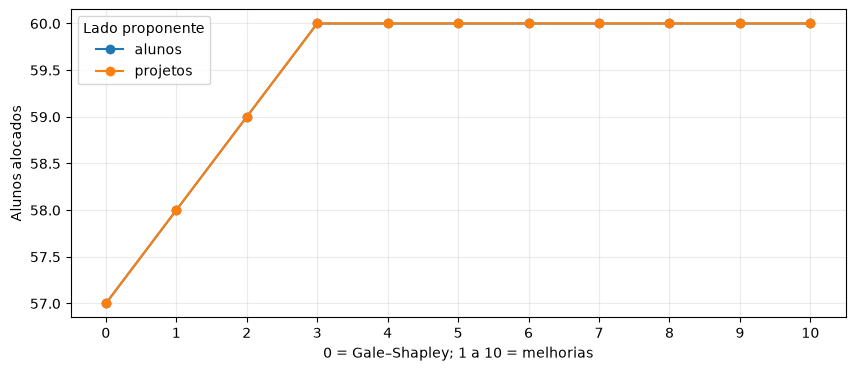

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
for direcao, dados in execucoes.items():
    h = dados["historico"]
    ax.plot([r.numero for r in h], [len(r.pares) for r in h], marker="o", label=direcao)
ax.set(xlabel="0 = Gale–Shapley; 1 a 10 = melhorias", ylabel="Alunos alocados")
ax.set_xticks(range(11))
ax.grid(alpha=0.25)
ax.legend(title="Lado proponente")
plt.show()

A seguir, desenhamos o estado inicial e os dez resultados. Cada figura coloca as
duas direções lado a lado. Os pares de cada estado são impressos antes da figura,
inclusive nas rodadas em que não houve mudança.

Gale–Shapley inicial | alunos: [('A1', 'P1'), ('A2', 'P1'), ('A8', 'P6'), ('A11', 'P12'), ('A14', 'P15'), ('A18', 'P8'), ('A23', 'P9'), ('A25', 'P34'), ('A26', 'P9'), ('A31', 'P12'), ('A32', 'P2'), ('A33', 'P3'), ('A34', 'P4'), ('A35', 'P5'), ('A41', 'P14'), ('A42', 'P16'), ('A43', 'P14'), ('A44', 'P15'), ('A46', 'P43'), ('A48', 'P26'), ('A50', 'P10'), ('A55', 'P35'), ('A56', 'P36'), ('A58', 'P47'), ('A60', 'P3'), ('A61', 'P37'), ('A62', 'P38'), ('A63', 'P39'), ('A64', 'P30'), ('A68', 'P36'), ('A69', 'P29'), ('A73', 'P45'), ('A81', 'P27'), ('A82', 'P2'), ('A83', 'P27'), ('A84', 'P40'), ('A85', 'P5'), ('A91', 'P24'), ('A93', 'P26'), ('A94', 'P45'), ('A100', 'P20'), ('A104', 'P25'), ('A107', 'P41'), ('A117', 'P7'), ('A127', 'P28'), ('A129', 'P29'), ('A137', 'P21'), ('A144', 'P22'), ('A157', 'P18'), ('A159', 'P49'), ('A161', 'P17'), ('A177', 'P18'), ('A187', 'P7'), ('A188', 'P8'), ('A196', 'P43'), ('A197', 'P41'), ('A200', 'P10')]
Gale–Shapley inicial | projetos: [('A1', 'P1'), ('A2', 'P1

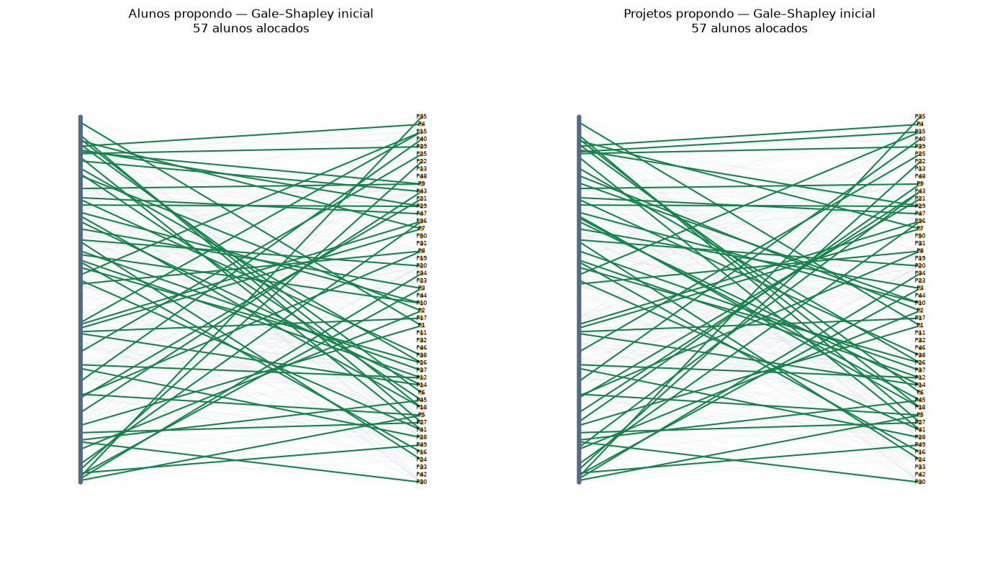

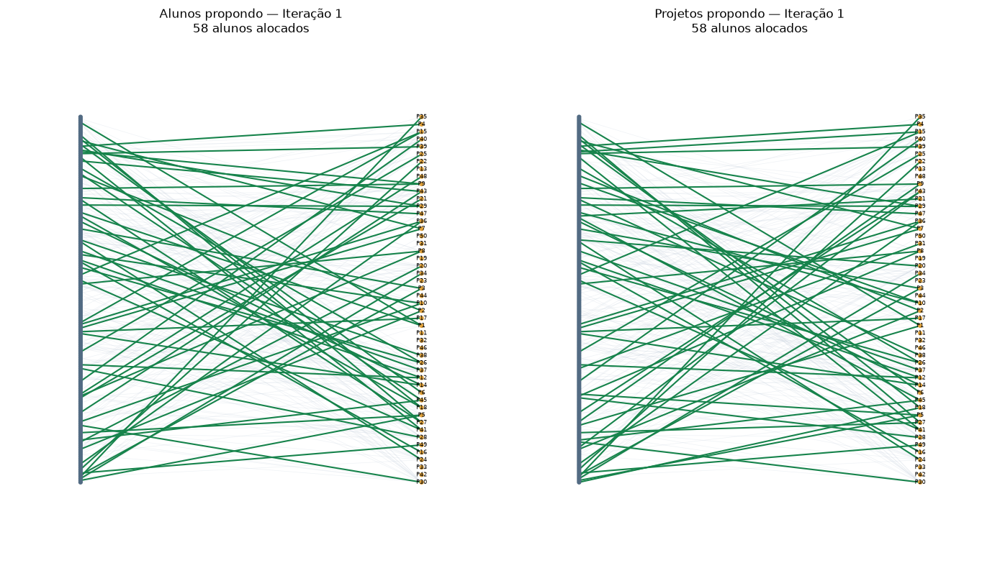

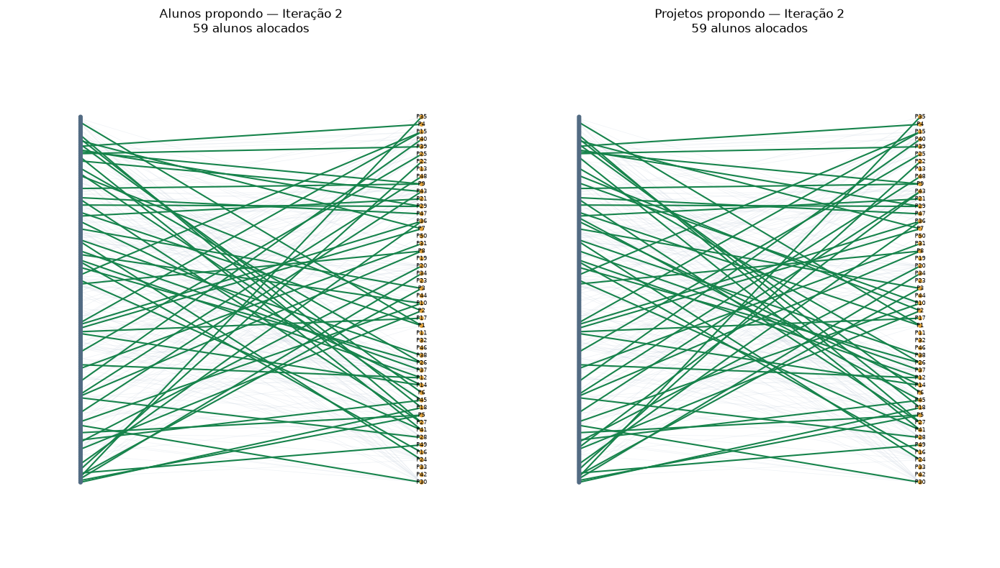

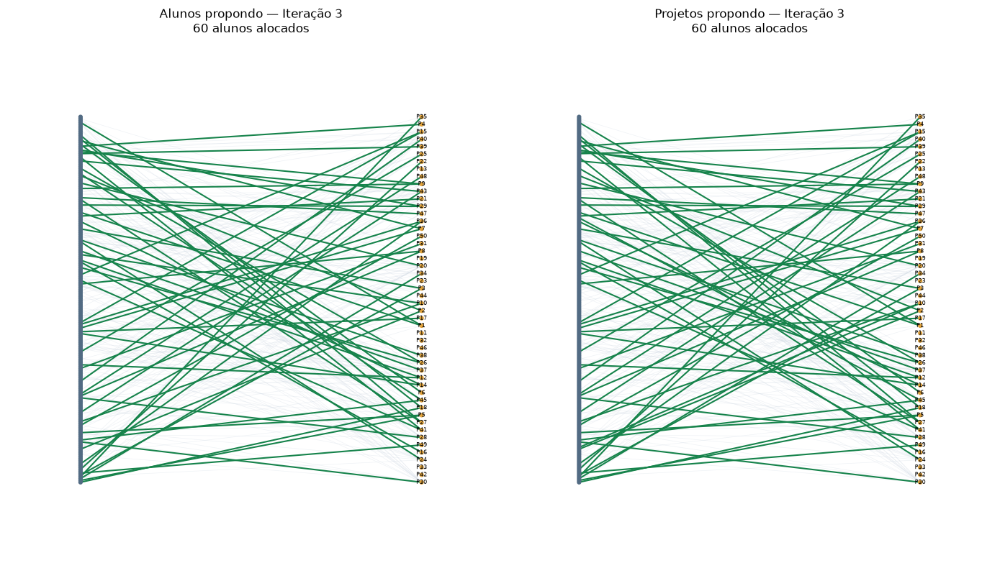

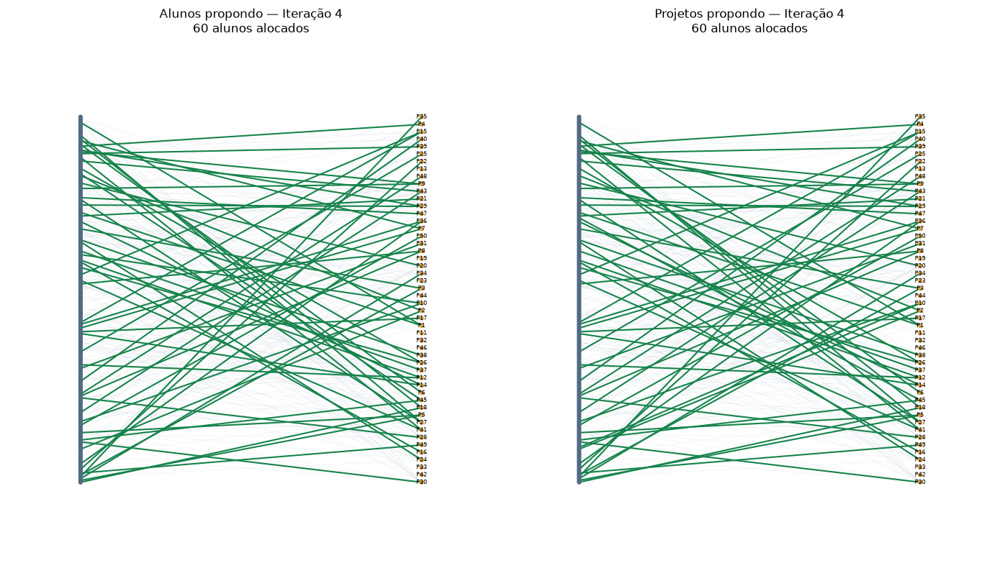

...

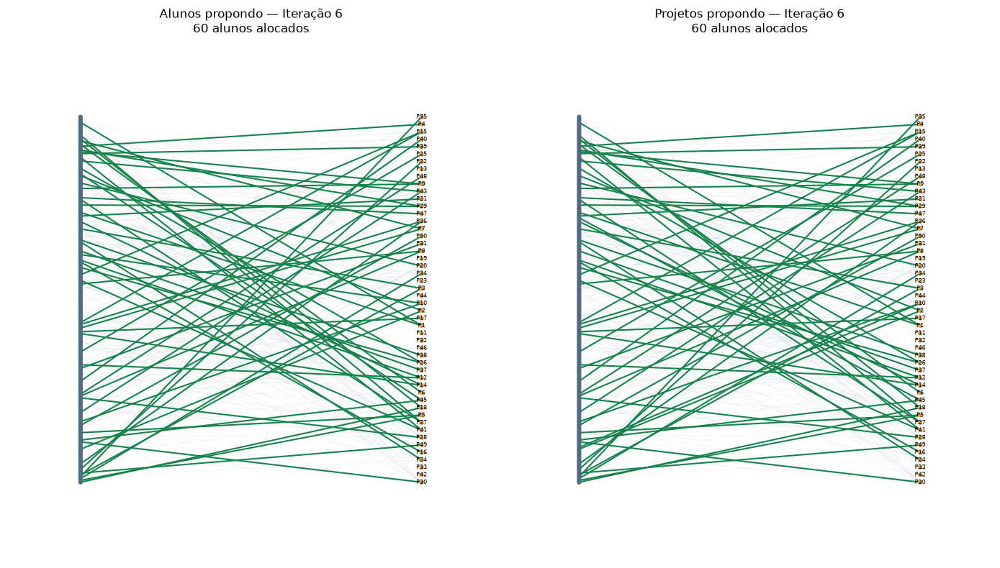

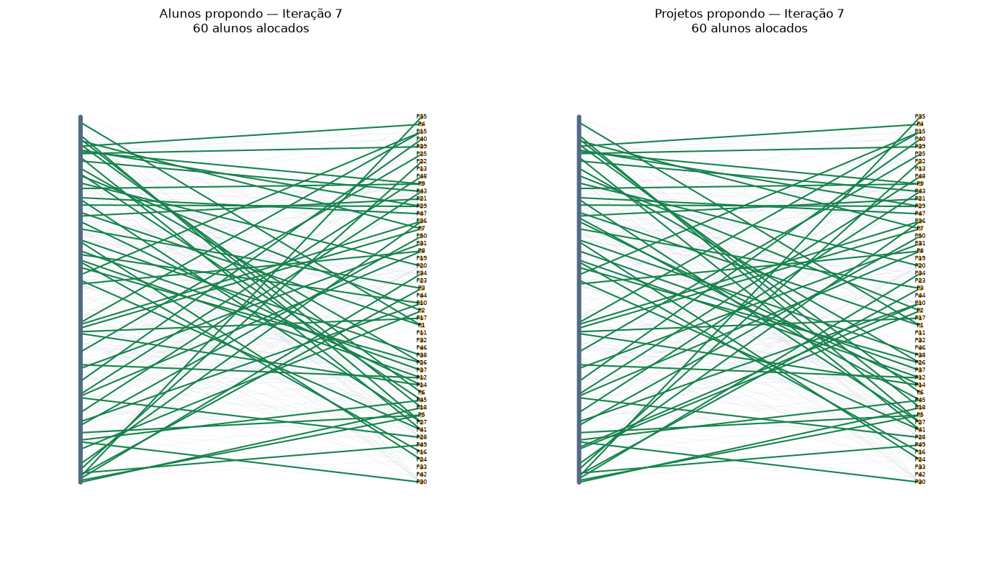

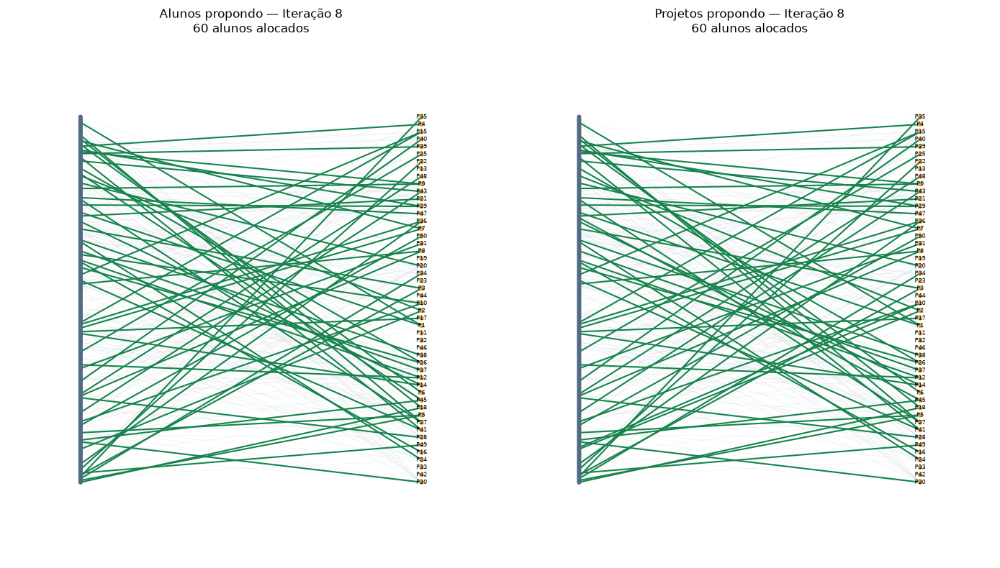

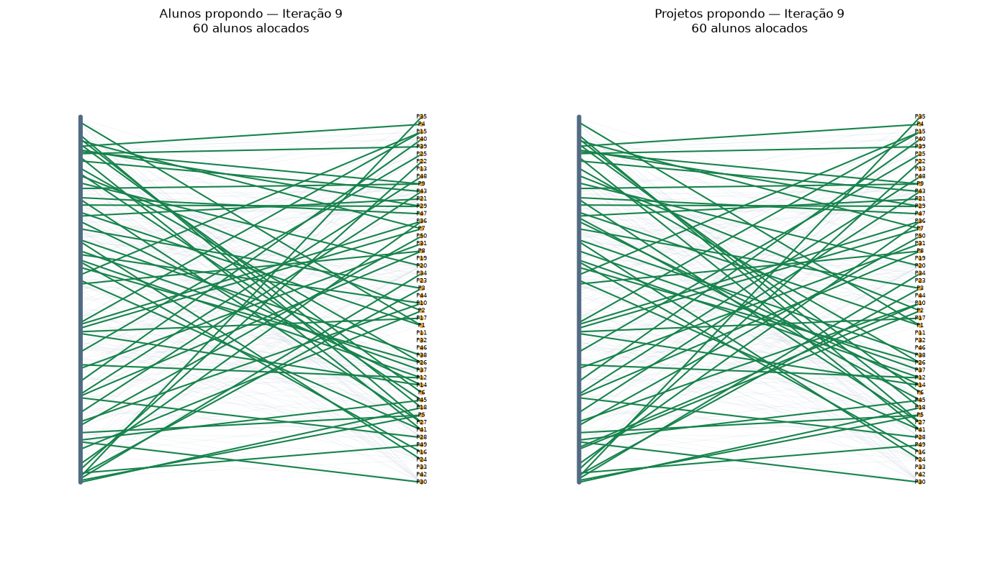

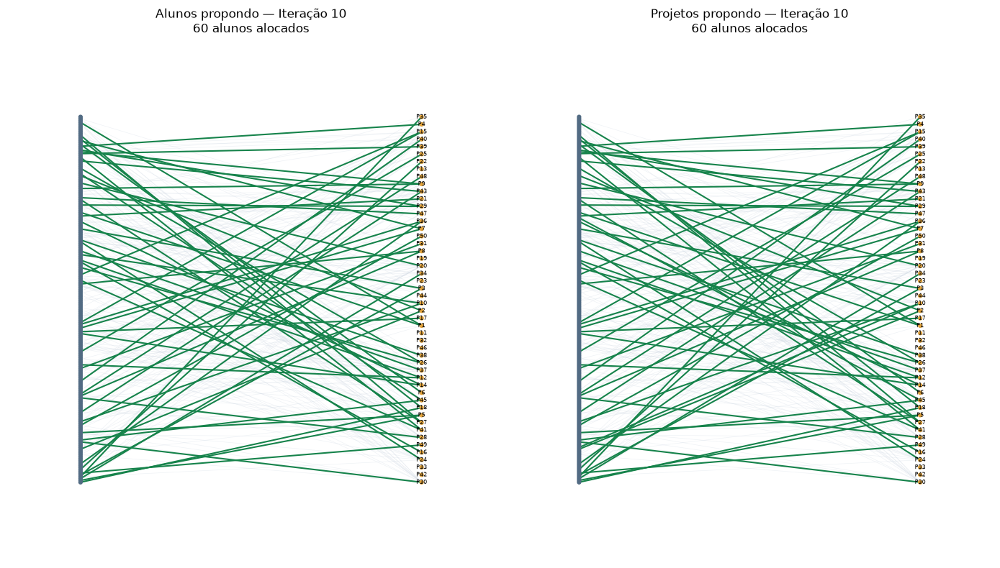

In [11]:
for numero in range(11):
    fig, axes = plt.subplots(1, 2, figsize=(14, 8))
    for ax, (direcao, dados) in zip(axes, execucoes.items()):
        rodada = dados["historico"][numero]
        estado = "Gale–Shapley inicial" if numero == 0 else f"Iteração {numero}"
        desenhar_grafo(ax, dados["alunos"], dados["projetos"], rodada.pares,
                      f"{direcao.capitalize()} propondo — {estado}\n{len(rodada.pares)} alunos alocados")
        print(f"{estado} | {direcao}:", rodada.pares)
    fig.tight_layout()
    plt.show()

Para acompanhar uma realocação, `desenhar_tentativa` divide o caminho em três
painéis: a proposta, a alocação provisória e a decisão após verificar a estabilidade.

Abaixo mostramos um caminho aceito e um rejeitado de cada direção. Nos rejeitados,
o terceiro painel recupera as ligações anteriores e destaca a proposta recusada em
vermelho. Os pares que causaram o bloqueio aparecem no texto acima da figura.
As contagens de todas as tentativas estão nas tabelas das rodadas.


Propostas dos alunos
Caminho: [('A6', 'P10'), ('A200', 'P1'), ('A1', 'P30'), ('A64', 'P20'), ('A100', 'P38'), ('A62', 'P27'), ('A83', 'P5'), ('A35', 'P48')]
Pares bloqueadores na simulação: []
Caminho: [('A4', 'P3'), ('A33', 'P30'), ('A64', 'P20'), ('A100', 'P38'), ('A62', 'P27'), ('A83', 'P5'), ('A35', 'P48')]
Pares bloqueadores na simulação: [('A33', 'P3')]

Propostas dos projetos
Caminho: [('A17', 'P18'), ('A157', 'P21'), ('A137', 'P28'), ('A127', 'P31')]
Pares bloqueadores na simulação: []
Caminho: [('A4', 'P3'), ('A33', 'P30'), ('A64', 'P20'), ('A100', 'P38'), ('A62', 'P27'), ('A83', 'P5'), ('A35', 'P48')]
Pares bloqueadores na simulação: [('A33', 'P3')]


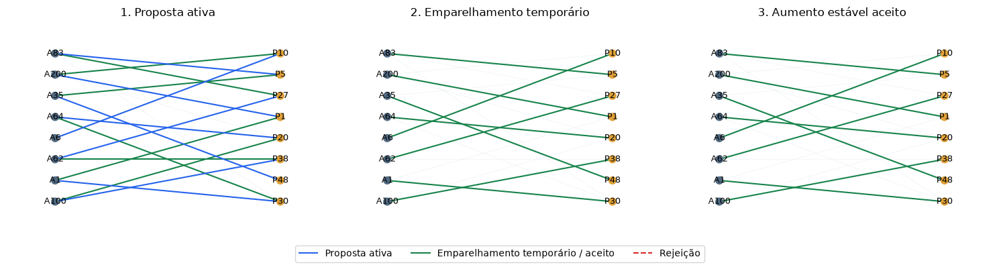

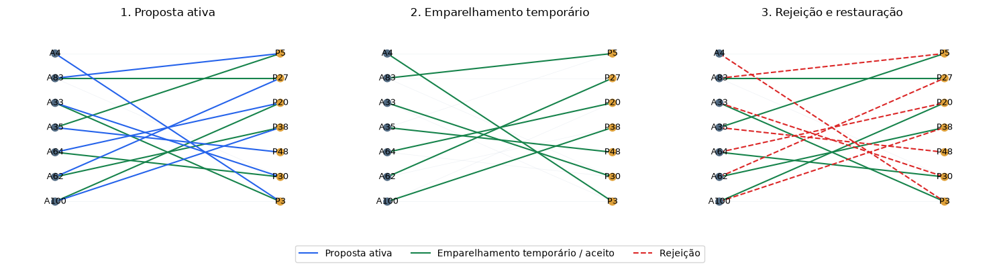

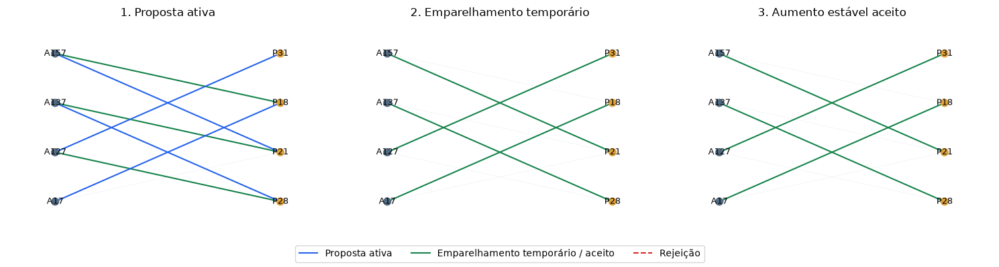

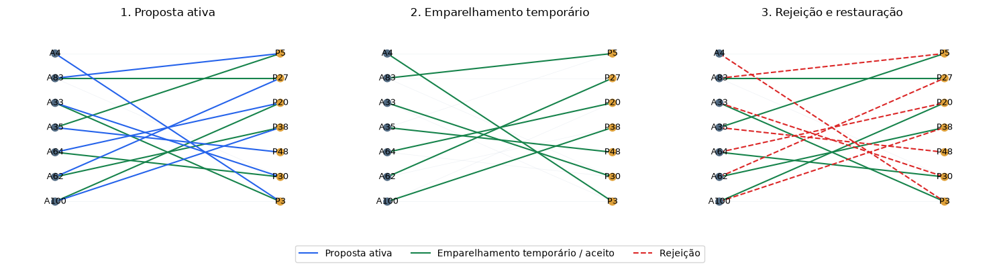

In [12]:
for direcao, dados in execucoes.items():
    exemplos = [e for r in dados["historico"] for e in r.exemplos]
    print("\nPropostas dos", direcao)
    for rejeitada in (False, True):
        exemplo = next((e for e in exemplos if bool(e.bloqueadores) == rejeitada), None)
        if exemplo is not None:
            print("Caminho:", exemplo.propostas)
            print("Pares bloqueadores na simulação:", exemplo.bloqueadores)
            fig = desenhar_tentativa(dados["alunos"], dados["projetos"], exemplo)
            plt.show()

Por fim, vamos exibir o índice de procura e a matriz de emparelhamentos de cada
direção. A tabela dos projetos propondo é a proposta final solicitada no enunciado.

As duas execuções atendem 60 alunos e compartilham 58 pares. Na direção dos alunos,
A50 fica com P10 e A94 com P45; na dos projetos, essas vagas ficam com A10 e A53.
A comparação ao fim da célula mostra essas diferenças.

In [13]:
for direcao, dados in execucoes.items():
    print("\nPROPOSTA FINAL" if direcao == "projetos" else "\nCOMPARAÇÃO")
    print("Lado proponente:", direcao)
    print("Índice de preferência por projeto:")
    mostrar_tabela(indices_preferencia(dados["alunos"], dados["projetos"]))
    print("Matriz final dos emparelhamentos:")
    mostrar_tabela(tabela_final(dados["alunos"]))

pares_alunos = set(execucoes["alunos"]["historico"][-1].pares)
pares_projetos = set(execucoes["projetos"]["historico"][-1].pares)
print("Pares em comum:", len(pares_alunos & pares_projetos))
print("Somente em alunos propondo:", sorted(pares_alunos - pares_projetos))
print("Somente em projetos propondo:", sorted(pares_projetos - pares_alunos))


COMPARAÇÃO
Lado proponente: alunos
Índice de preferência por projeto:
Matriz final dos emparelhamentos:

PROPOSTA FINAL
Lado proponente: projetos
Índice de preferência por projeto:
Matriz final dos emparelhamentos:
Pares em comum: 58
Somente em alunos propondo: [('A50', 'P10'), ('A94', 'P45')]
Somente em projetos propondo: [('A10', 'P10'), ('A53', 'P45')]


Projeto,1ª escolha,2ª escolha,3ª escolha,Índice,Elegíveis,Vagas,Ocupadas
P1,5,3,5,26,5,2,2
P2,8,2,0,28,3,2,2
P3,4,7,0,26,9,2,2
P4,9,4,10,45,4,1,1
P5,5,0,12,27,10,2,2
P6,6,1,0,20,1,2,1
P7,11,4,0,41,2,2,2
P8,10,2,13,47,5,2,2
P9,4,6,9,33,8,2,2
P10,6,1,14,34,10,2,2


Aluno,Projeto,Nota,Escolha do aluno,Posição no projeto,Candidatos elegíveis
A1,P50,5,3,1,1
A2,P1,5,1,1,5
A3,—,3,—,—,—
A4,—,4,—,—,—
A5,—,3,—,—,—
A6,P10,4,3,2,10
A7,—,4,—,—,—
A8,P6,5,1,1,1
A9,—,3,—,—,—
A10,—,4,—,—,—


Projeto,1ª escolha,2ª escolha,3ª escolha,Índice,Elegíveis,Vagas,Ocupadas
P1,5,3,5,26,5,2,2
P2,8,2,0,28,3,2,2
P3,4,7,0,26,9,2,2
P4,9,4,10,45,4,1,1
P5,5,0,12,27,10,2,2
P6,6,1,0,20,1,2,1
P7,11,4,0,41,2,2,2
P8,10,2,13,47,5,2,2
P9,4,6,9,33,8,2,2
P10,6,1,14,34,10,2,2


Aluno,Projeto,Nota,Escolha do aluno,Posição no projeto,Candidatos elegíveis
A1,P50,5,3,1,1
A2,P1,5,1,1,5
A3,—,3,—,—,—
A4,—,4,—,—,—
A5,—,3,—,—,—
A6,P10,4,3,2,10
A7,—,4,—,—,—
A8,P6,5,1,1,1
A9,—,3,—,—,—
A10,P10,4,3,2,10


## Comparação sem exigir estabilidade

Vamos repetir a busca por caminhos aumentantes a partir de cada uma das soluções
estáveis: alunos propondo e projetos propondo. Em cada caso, partimos dos 60 pares
já obtidos e fazemos dez novas iterações, com até um aumento por rodada.

A regra de busca é a mesma nas duas execuções; o que muda é a alocação inicial.
Aceitamos as realocações mesmo quando criam pares bloqueadores. Continuam valendo
as preferências dos alunos, as notas mínimas e as capacidades dos projetos.

Cada execução usa uma cópia da alocação anterior. A estabilidade é calculada apenas
para comparar os resultados, sem impedir uma troca.

In [14]:
"""Experimento de aumento sem impor estabilidade à alocação."""



def executar_sem_estabilidade(
    algoritmo: GaleShapley, total_iteracoes: int = 10
) -> list[IteracaoEmparelhamento]:
    """Parte da alocação atual e aceita até um caminho aumentante por rodada."""
    if total_iteracoes < 1:
        raise ValueError("O número de iterações deve ser pelo menos 1.")

    historico = []
    for numero in range(total_iteracoes + 1):
        caminho = []
        if numero > 0:
            for aluno in algoritmo.alunos:
                if aluno.projeto is not None:
                    continue
                caminhos = algoritmo._caminhos_alternados(aluno, {aluno}, set())
                caminho = next(caminhos, [])
                if caminho:
                    break

            # Abre as vagas do caminho e depois cria as novas relações.
            for aluno, _ in caminho:
                if aluno.projeto is not None:
                    aluno.projeto.alunos.remove(aluno)
                    aluno.projeto = None
            for aluno, projeto in caminho:
                algoritmo.cria_relacao(aluno, len(projeto.alunos), projeto)

        pares = [
            (a.label, a.projeto.label)
            for a in algoritmo.alunos if a.projeto is not None
        ]
        historico.append(
            IteracaoEmparelhamento(
                numero=numero,
                pares=pares,
                caminho=[(a.label, p.label) for a, p in caminho],
                tentativas=int(bool(caminho)),
                # Apenas diagnóstico: os bloqueios não impedem o aumento.
                bloqueadores=algoritmo.checa_estabilidade(),
            )
        )

    return historico

In [15]:
execucoes_sem = {}
for direcao in ("alunos", "projetos"):
    alunos_sem, projetos_sem = create_instances(str(entrada))
    algoritmo_sem = GaleShapley(alunos_sem, projetos_sem)
    por_aluno = {a.label: a for a in alunos_sem}
    por_projeto = {p.label: p for p in projetos_sem}
    pares_estaveis = execucoes[direcao]["historico"][-1].pares

    for aluno_id, projeto_id in pares_estaveis:
        projeto = por_projeto[projeto_id]
        algoritmo_sem.cria_relacao(
            por_aluno[aluno_id], len(projeto.alunos), projeto
        )

    historico_sem = executar_sem_estabilidade(algoritmo_sem, total_iteracoes=10)
    execucoes_sem[direcao] = {
        "alunos": alunos_sem,
        "projetos": projetos_sem,
        "historico": historico_sem,
    }
    print("\nOrigem: solução estável de", direcao, "propondo")
    mostrar_tabela([
        {
            "Estado": "Solução estável inicial" if r.numero == 0 else r.numero,
            "Alocados": len(r.pares),
            "Pares bloqueadores": len(r.bloqueadores),
            "Houve aumento?": bool(r.caminho),
        }
        for r in historico_sem
    ])
    for rodada in historico_sem[1:]:
        if rodada.caminho:
            print(f"Iteração {rodada.numero} — novos pares:", rodada.caminho)

    # Confere que a solução estável anterior não foi alterada.
    pares_originais = [
        (a.label, a.projeto.label)
        for a in execucoes[direcao]["alunos"] if a.projeto is not None
    ]
    assert pares_originais == pares_estaveis


Origem: solução estável de alunos propondo
Iteração 1 — novos pares: [('A4', 'P3'), ('A33', 'P30'), ('A64', 'P20'), ('A24', 'P10'), ('A6', 'P40'), ('A84', 'P4'), ('A34', 'P15'), ('A44', 'P12'), ('A31', 'P2'), ('A82', 'P44')]
Iteração 2 — novos pares: [('A7', 'P41'), ('A107', 'P1'), ('A200', 'P10'), ('A50', 'P43'), ('A196', 'P31')]
Iteração 3 — novos pares: [('A10', 'P43'), ('A50', 'P10'), ('A200', 'P1'), ('A107', 'P41'), ('A197', 'P23')]

Origem: solução estável de projetos propondo
Iteração 1 — novos pares: [('A4', 'P3'), ('A33', 'P30'), ('A64', 'P20'), ('A24', 'P10'), ('A6', 'P40'), ('A84', 'P4'), ('A34', 'P15'), ('A44', 'P12'), ('A31', 'P2'), ('A82', 'P44')]
Iteração 2 — novos pares: [('A7', 'P41'), ('A107', 'P1'), ('A200', 'P10'), ('A10', 'P43'), ('A196', 'P31')]
Iteração 3 — novos pares: [('A27', 'P41'), ('A197', 'P23')]


Estado,Alocados,Pares bloqueadores,Houve aumento?
Solução estável inicial,60,0,False
1,61,3,True
2,62,5,True
3,63,5,True
4,63,5,False
5,63,5,False
6,63,5,False
7,63,5,False
8,63,5,False
9,63,5,False


Estado,Alocados,Pares bloqueadores,Houve aumento?
Solução estável inicial,60,0,False
1,61,3,True
2,62,5,True
3,63,6,True
4,63,6,False
5,63,6,False
6,63,6,False
7,63,6,False
8,63,6,False
9,63,6,False


O gráfico abaixo compara o número de alocados e de pares bloqueadores das duas
trajetórias. Em ambas, o estado 0 é a solução estável usada como ponto de partida;
as dez tentativas de aumento são os estados de 1 a 10.

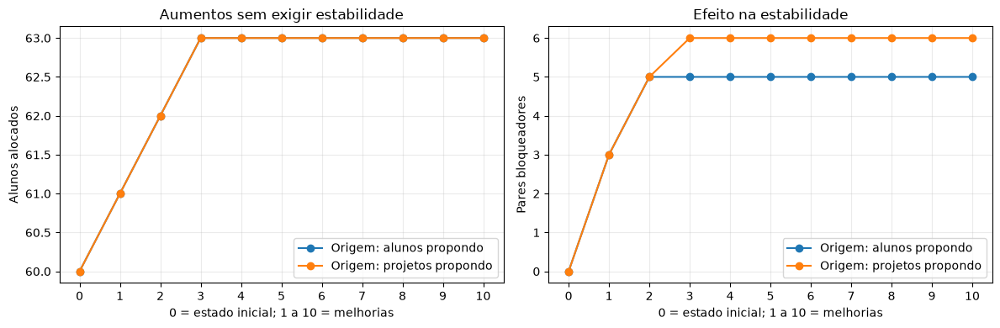

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for direcao, dados in execucoes_sem.items():
    historico_sem = dados["historico"]
    numeros = [r.numero for r in historico_sem]
    axes[0].plot(
        numeros, [len(r.pares) for r in historico_sem],
        marker="o", label=f"Origem: {direcao} propondo",
    )
    axes[1].plot(
        numeros, [len(r.bloqueadores) for r in historico_sem],
        marker="o", label=f"Origem: {direcao} propondo",
    )
axes[0].set(ylabel="Alunos alocados", title="Aumentos sem exigir estabilidade")
axes[1].set(ylabel="Pares bloqueadores", title="Efeito na estabilidade")
for ax in axes:
    ax.set_xlabel("0 = estado inicial; 1 a 10 = melhorias")
    ax.set_xticks(range(11))
    ax.grid(alpha=0.25)
    ax.legend()
fig.tight_layout()
plt.show()

A seguir, colocamos as duas trajetórias lado a lado em cada uma das dez iterações.
Os títulos indicam qual solução de Gale–Shapley deu origem à execução. As arestas
verdes representam as alocações, sem indicar se o emparelhamento é estável.

Iteração 1 | origem: alunos: [('A1', 'P50'), ('A2', 'P1'), ('A4', 'P3'), ('A6', 'P40'), ('A8', 'P6'), ('A11', 'P12'), ('A14', 'P15'), ('A17', 'P18'), ('A18', 'P8'), ('A23', 'P9'), ('A24', 'P10'), ('A25', 'P34'), ('A26', 'P9'), ('A31', 'P2'), ('A32', 'P2'), ('A33', 'P30'), ('A34', 'P15'), ('A35', 'P48'), ('A41', 'P14'), ('A42', 'P16'), ('A43', 'P14'), ('A44', 'P12'), ('A46', 'P43'), ('A48', 'P26'), ('A50', 'P10'), ('A55', 'P35'), ('A56', 'P36'), ('A58', 'P47'), ('A60', 'P3'), ('A61', 'P37'), ('A62', 'P27'), ('A63', 'P39'), ('A64', 'P20'), ('A68', 'P36'), ('A69', 'P29'), ('A73', 'P45'), ('A81', 'P27'), ('A82', 'P44'), ('A83', 'P5'), ('A84', 'P4'), ('A85', 'P5'), ('A91', 'P24'), ('A93', 'P26'), ('A94', 'P45'), ('A100', 'P38'), ('A104', 'P25'), ('A107', 'P41'), ('A117', 'P7'), ('A127', 'P31'), ('A129', 'P29'), ('A137', 'P28'), ('A144', 'P22'), ('A157', 'P21'), ('A159', 'P49'), ('A161', 'P17'), ('A177', 'P18'), ('A187', 'P7'), ('A188', 'P8'), ('A196', 'P43'), ('A197', 'P41'), ('A200', 'P1')

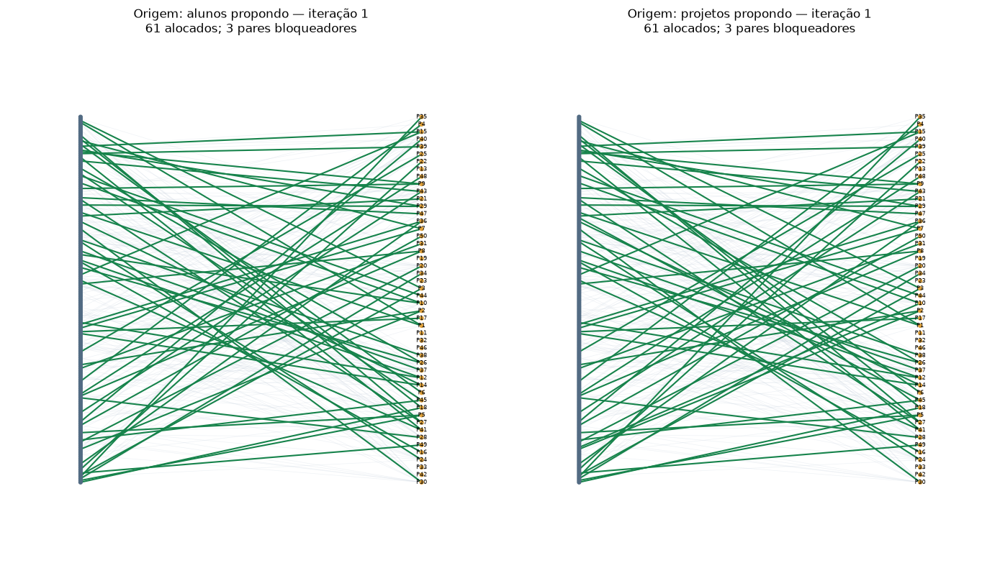

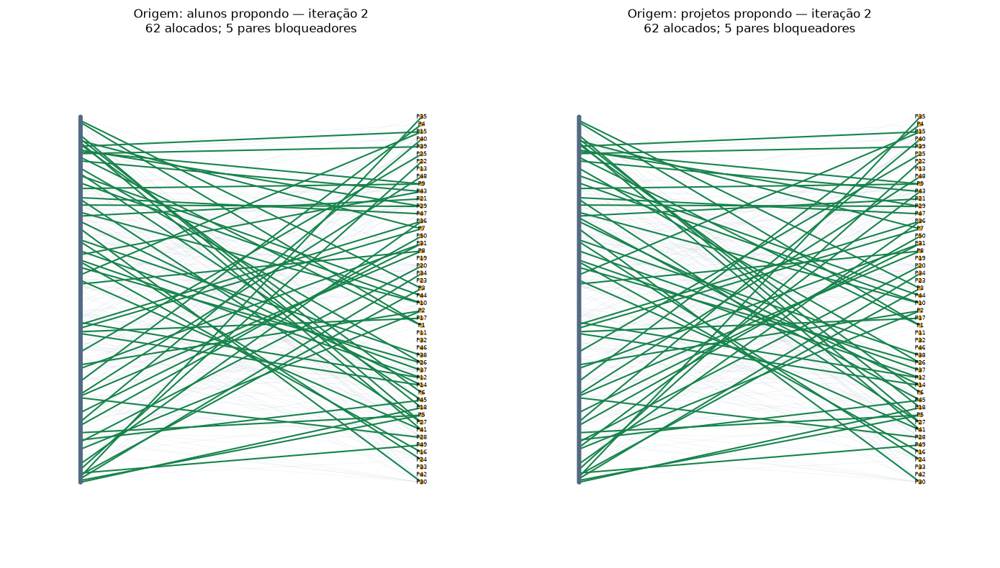

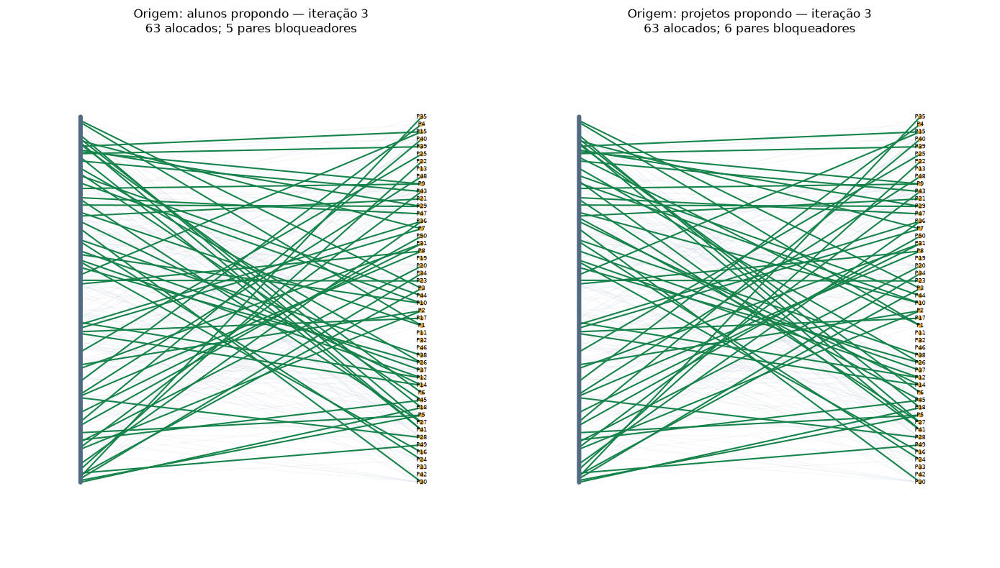

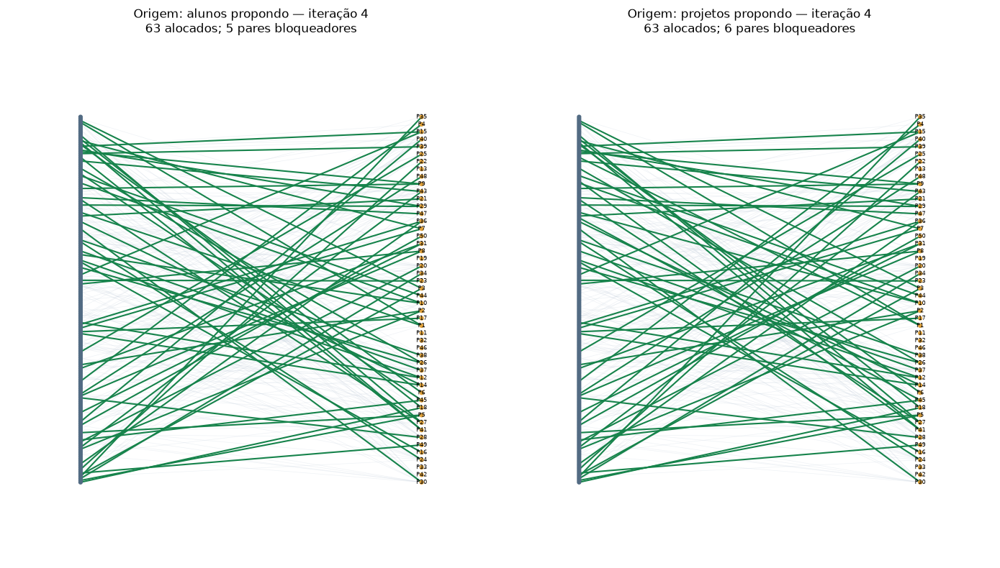

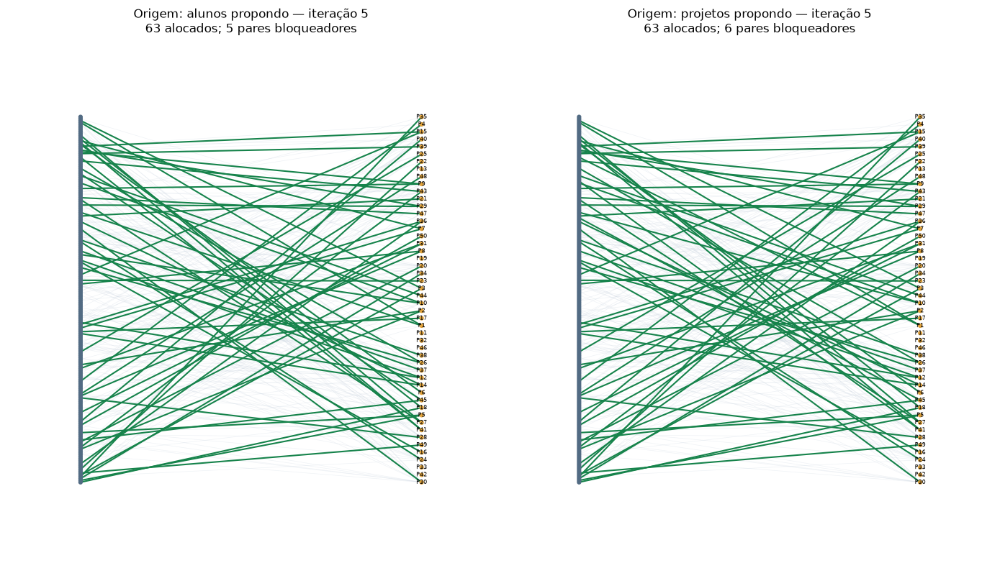

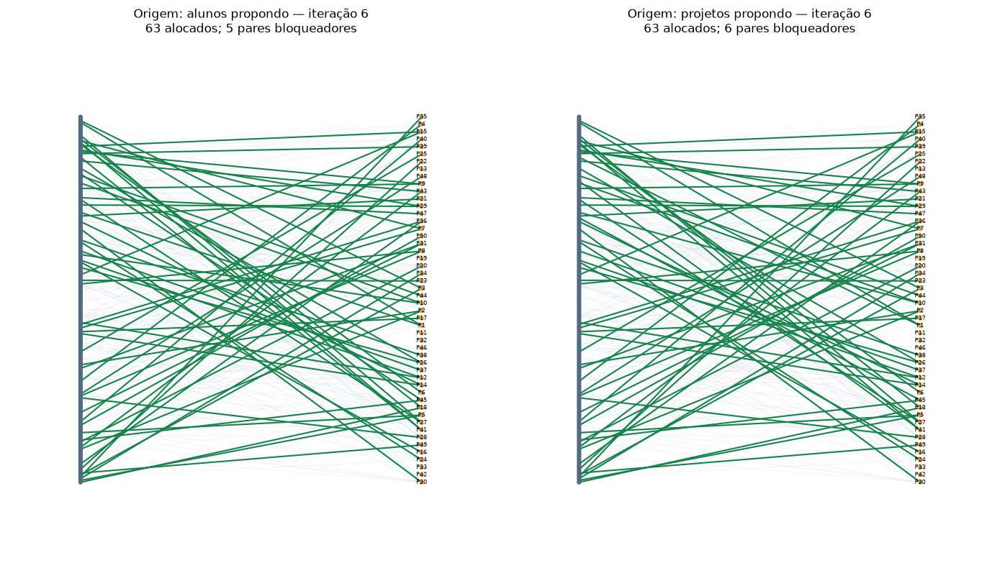

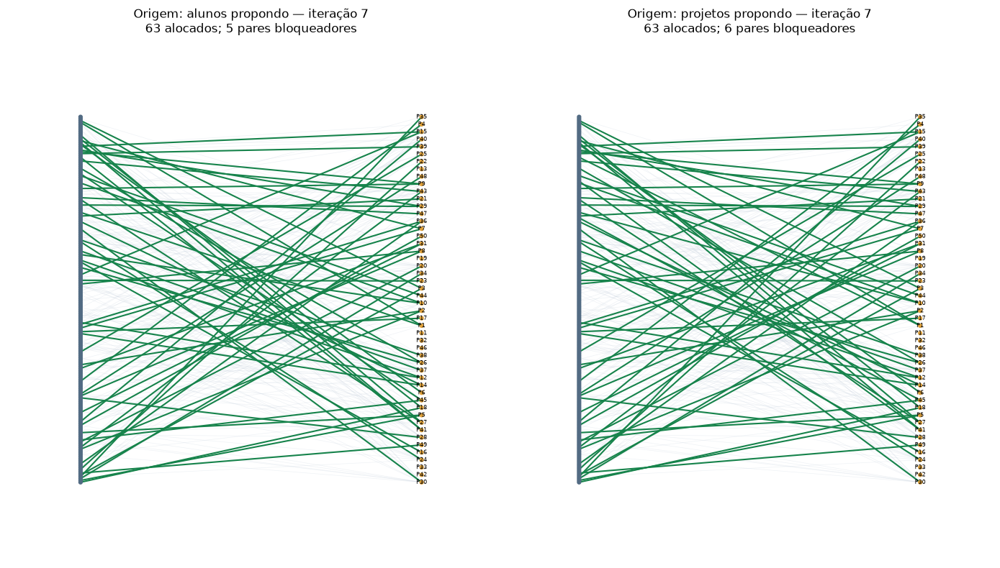

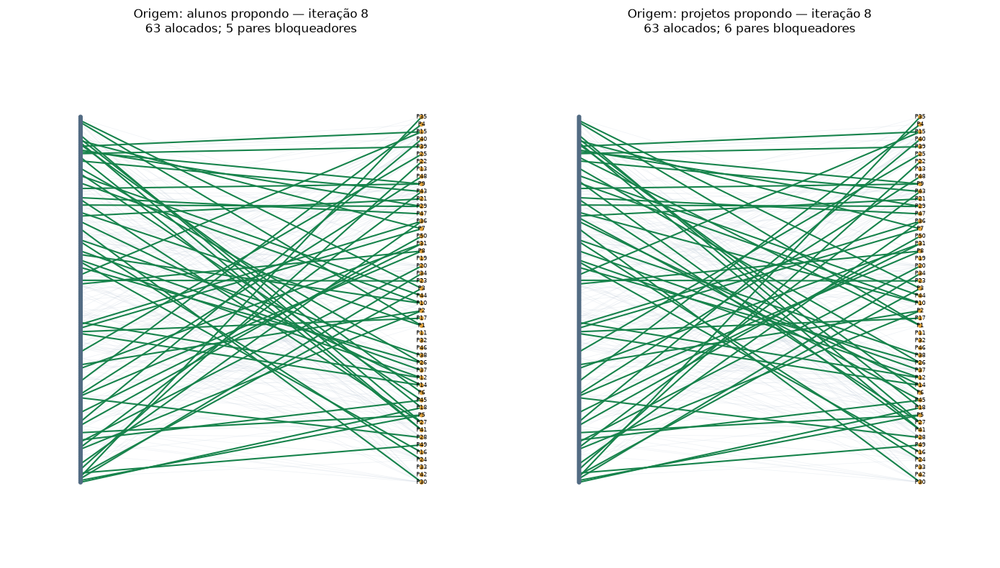

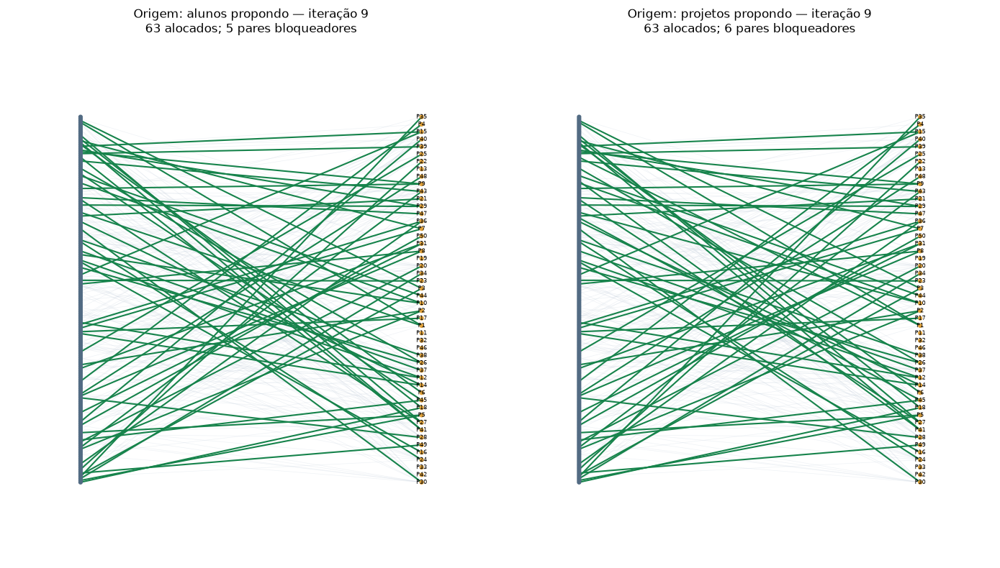

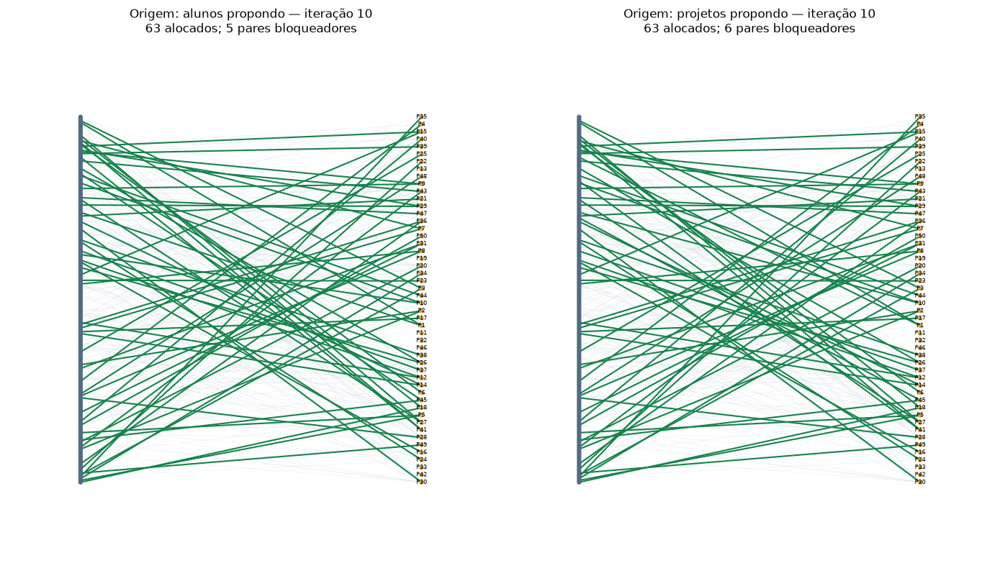

In [17]:
for numero in range(1, 11):
    fig, axes = plt.subplots(1, 2, figsize=(14, 8))
    for ax, (direcao, dados) in zip(axes, execucoes_sem.items()):
        rodada = dados["historico"][numero]
        titulo = (
            f"Origem: {direcao} propondo — iteração {numero}\n"
            f"{len(rodada.pares)} alocados; "
            f"{len(rodada.bloqueadores)} pares bloqueadores"
        )
        desenhar_grafo(
            ax, dados["alunos"], dados["projetos"], rodada.pares, titulo
        )
        print(f"Iteração {numero} | origem: {direcao}:", rodada.pares)
    fig.tight_layout()
    plt.show()

Por fim, mostramos a matriz final de cada trajetória e seus pares bloqueadores.
As classificações são calculadas da mesma forma que nas tabelas anteriores.
Essa comparação não substitui a proposta estável da direção dos projetos.

In [18]:
for direcao, dados in execucoes_sem.items():
    alunos_sem = dados["alunos"]
    projetos_sem = dados["projetos"]
    historico_sem = dados["historico"]
    pares_sem = historico_sem[-1].pares
    aceitos_sem = [a for p in projetos_sem for a in p.alunos]
    assert len(aceitos_sem) == len(set(aceitos_sem)) == len(pares_sem)
    for p in projetos_sem:
        assert len(p.alunos) <= p.vagas
        assert all(
            a.projeto is p and p in a.preferencias and a.nota >= p.nota_min
            for a in p.alunos
        )
    for a in alunos_sem:
        assert a.projeto is None or a in a.projeto.alunos

    print("\nOrigem: solução estável de", direcao, "propondo")
    print("Alunos alocados:", len(pares_sem))
    print("Ganho em relação à origem:", len(pares_sem) - len(historico_sem[0].pares))
    print("Pares bloqueadores finais:", historico_sem[-1].bloqueadores)
    mostrar_tabela(tabela_final(alunos_sem))

pares_sem_alunos = set(execucoes_sem["alunos"]["historico"][-1].pares)
pares_sem_projetos = set(execucoes_sem["projetos"]["historico"][-1].pares)
print("Pares em comum entre as trajetórias:", len(pares_sem_alunos & pares_sem_projetos))
print("Somente na origem alunos:", sorted(pares_sem_alunos - pares_sem_projetos))
print("Somente na origem projetos:", sorted(pares_sem_projetos - pares_sem_alunos))


Origem: solução estável de alunos propondo
Alunos alocados: 63
Ganho em relação à origem: 3
Pares bloqueadores finais: [('A31', 'P12'), ('A33', 'P3'), ('A34', 'P40'), ('A196', 'P43'), ('A197', 'P41')]

Origem: solução estável de projetos propondo
Alunos alocados: 63
Ganho em relação à origem: 3
Pares bloqueadores finais: [('A31', 'P12'), ('A33', 'P3'), ('A34', 'P40'), ('A107', 'P41'), ('A196', 'P43'), ('A197', 'P41')]
Pares em comum entre as trajetórias: 59
Somente na origem alunos: [('A107', 'P41'), ('A200', 'P1'), ('A50', 'P10'), ('A94', 'P45')]
Somente na origem projetos: [('A107', 'P1'), ('A200', 'P10'), ('A27', 'P41'), ('A53', 'P45')]


Aluno,Projeto,Nota,Escolha do aluno,Posição no projeto,Candidatos elegíveis
A1,P50,5,3,1,1
A2,P1,5,1,1,5
A3,—,3,—,—,—
A4,P3,4,2,5,9
A5,—,3,—,—,—
A6,P40,4,1,3,14
A7,P41,4,1,3,6
A8,P6,5,1,1,1
A9,—,3,—,—,—
A10,P43,4,2,2,9


Aluno,Projeto,Nota,Escolha do aluno,Posição no projeto,Candidatos elegíveis
A1,P50,5,3,1,1
A2,P1,5,1,1,5
A3,—,3,—,—,—
A4,P3,4,2,5,9
A5,—,3,—,—,—
A6,P40,4,1,3,14
A7,P41,4,1,3,6
A8,P6,5,1,1,1
A9,—,3,—,—,—
A10,P43,4,2,2,9
